In [1]:
# import packages
import scimap as sm
import anndata as ad

Running SCIMAP  2.3.5


c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\mpl_scatter_density\__init__.py:4: UserWarning:

pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.

c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\tqdm\auto.py:21: TqdmWarning:

IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html



In [2]:
# Load the data that we saved in the last tutorial (with ROIs added)
adata = ad.read_h5ad('C:\\Users\\chuab\\Desktop\\SciMap_project\\scimapExampleData\\scimapExampleData.h5ad')

Compute the distances among cell types.


In [4]:
adata = sm.tl.spatial_distance (adata, phenotype='leiden_phenotype')

Processing Image: exemplar-001--unmicst_cell


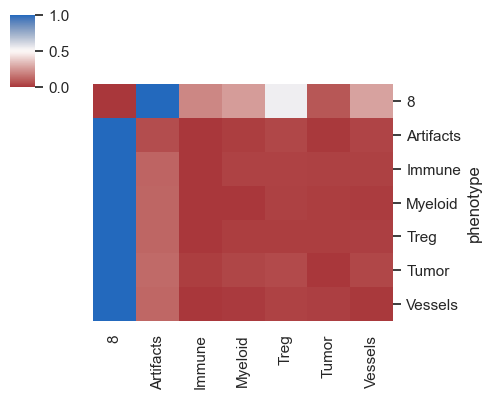

In [6]:
# This is one of the most complicated plotting functions in the package
# To start- let's get an overview with a heatmap

sm.pl.spatial_distance(adata, phenotype='leiden_phenotype', figsize=(5,4))

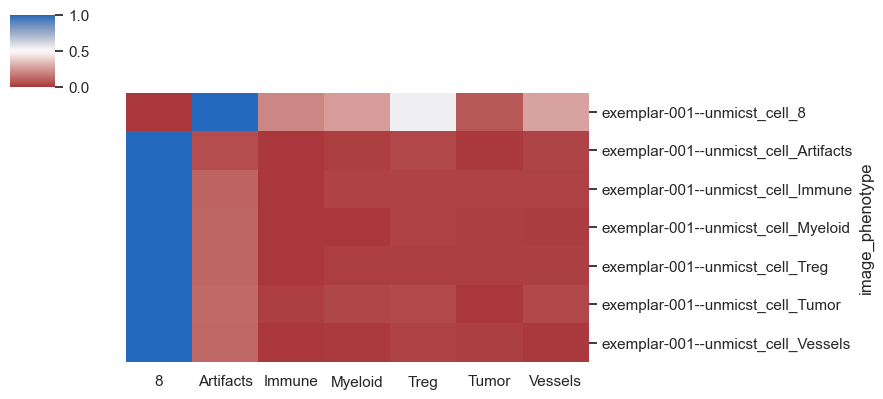

In [8]:
# For datasets containing multiple images, the default behavior averages the distances across all images. To analyze and plot the distances for each image individually, you should set heatmap_summarize to False.
sm.pl.spatial_distance (adata,phenotype='leiden_phenotype',  heatmap_summarize=False, figsize=(9,4))

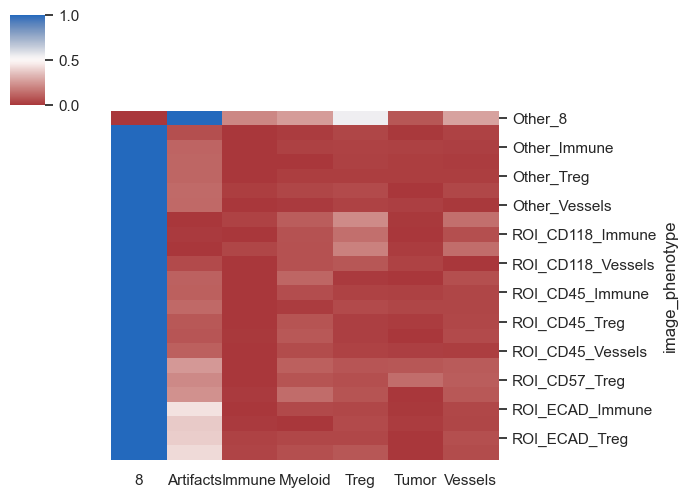

In [10]:
sm.pl.spatial_distance (adata, phenotype='leiden_phenotype', heatmap_summarize=False, imageid='ROI', figsize=(7,5))

In [13]:
print(adata.obs['leiden_phenotype'].unique())


['Tumor', 'Immune', 'Vessels', 'Myeloid', 'Treg', 'Artifacts', '8']
Categories (7, object): ['8', 'Artifacts', 'Immune', 'Myeloid', 'Treg', 'Tumor', 'Vessels']


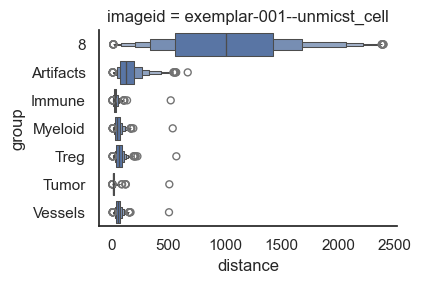

In [14]:
# Let's say there is an interest in identifying the cells closest to tumor cells; we will do the following analysis to address this interest.
# Numeric plot of the shortest distance of phenotypes from tumor cells

sm.pl.spatial_distance (adata,phenotype='leiden_phenotype', method='numeric',distance_from='Tumor', height=3, aspect=11/8)

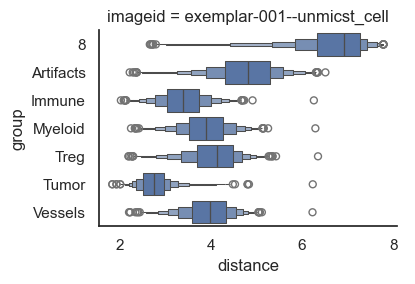

In [16]:
# log the x-axis to make the pattern more distinct.
sm.pl.spatial_distance (adata,phenotype='leiden_phenotype', method='numeric',distance_from='Tumor', log=True, height=3, aspect=11/8)

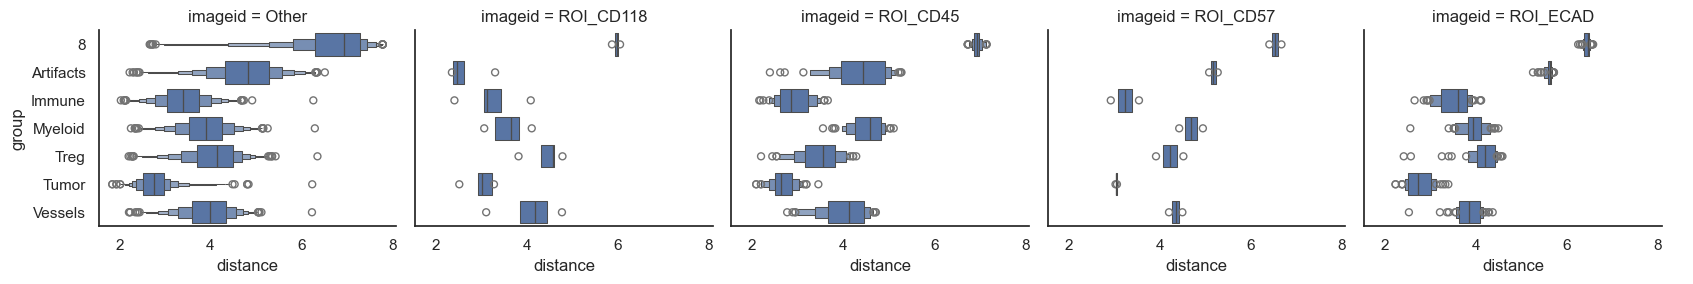

In [18]:
# Since our dataset doesn't include multiple images, we'll use the ROIs as a substitute once again, as the underlying concept remains the same.
sm.pl.spatial_distance (adata,phenotype='leiden_phenotype',  method='numeric',distance_from='Tumor', log=True, imageid='ROI', height=3, aspect=9/8)

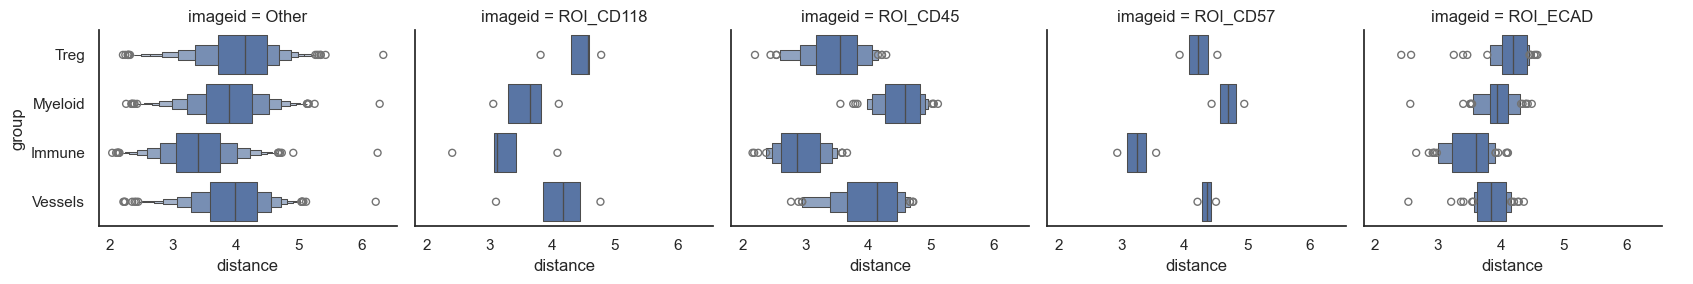

In [21]:
# Once narrowed down to a few cell types of interest. We can also subset and display only these selected cells.
# Use only categories that actually exist in your 'leiden_phenotype' column
distance_to = ['Treg', 'Myeloid', 'Immune', 'Vessels'] 

sm.pl.spatial_distance(
    adata, 
    phenotype='leiden_phenotype', 
    method='numeric', 
    distance_from='Tumor', 
    distance_to=distance_to, 
    log=True, 
    imageid='ROI', 
    height=3, 
    aspect=9/8
)


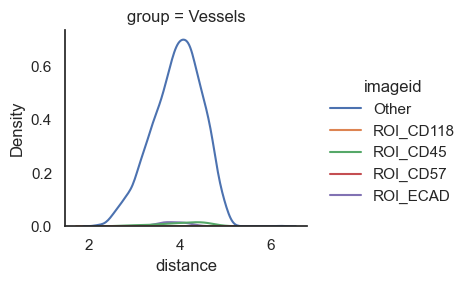

In [23]:
# We can also visualize this using distribution plots instead of box plots, which is particularly useful if you want to demonstrate that the distance between two cell types vary across different conditions. 
sm.pl.spatial_distance(
    adata, 
    phenotype='leiden_phenotype', 
    method='distribution', 
    distance_from='Tumor',     # Changed from 'ECAD+'
    distance_to='Vessels',     # Changed from 'SMA+'
    imageid='ROI', 
    log=True, 
    height=3, 
    aspect=9/8
)


In [24]:
# Save the results
adata.write('C:\\Users\\chuab\\Desktop\\SciMap_project\\scimapExampleData\\scimapExampleData.h5ad')

🤏 Cell-Cell Interaction / Proximity / Co-Occurance Analysis


In [25]:
# import packages
import scimap as sm
import anndata as ad
# Load the data that we saved in the last tutorial (with ROIs added)
adata = ad.read_h5ad('C:\\Users\\chuab\\Desktop\\SciMap_project\\scimapExampleData\\scimapExampleData.h5ad')

Run spatial interaction tool

In [27]:
adata = sm.tl.spatial_interaction (adata,
                                      phenotype='leiden_phenotype', 
                                  method='radius', 
                                  radius=70, 
                                  label='spatial_interaction_radius')

# if you would like to use set nearest neighbours use method = 'knn' and knn=10

Processing Image: ['exemplar-001--unmicst_cell']
Categories (1, object): ['exemplar-001--unmicst_cell']
Identifying neighbours within 70 pixels of every cell
Mapping phenotype to neighbors
Performing 1000 permutations
Consolidating the permutation results


Processing Image: ['exemplar-001--unmicst_cell']
Categories (1, object): ['exemplar-001--unmicst_cell']
Identifying neighbours within 30 pixels of every cell
Mapping phenotype to neighbors
Performing 1000 permutations
Consolidating the permutation results


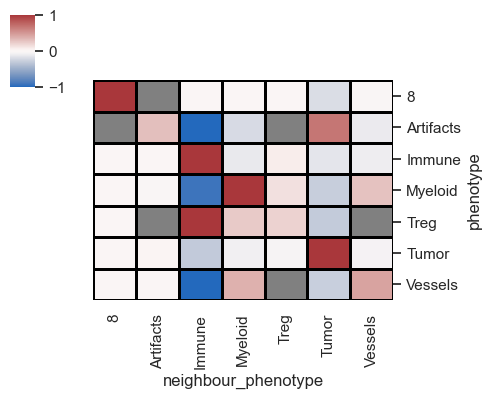

In [29]:
# 1. Run the tool first (this step NEEDS the phenotype argument)
sm.tl.spatial_interaction(adata, phenotype='leiden_phenotype')

# 2. Then plot (this step DOES NOT take the phenotype argument)
sm.pl.spatial_interaction(
    adata, 
    spatial_interaction='spatial_interaction',  # Default key name unless changed in step 1
    linewidths=0.75, 
    linecolor='black', 
    figsize=(5,4)
)

# In the depicted plot, red and blue signify the likelihood of two cell types being adjacent to each other, while grey denotes interactions that lack significance.

In [31]:
# rerun the analysis with passing ROI column 
adata = sm.tl.spatial_interaction(adata, 
                                  phenotype='leiden_phenotype',
                                  method='radius', 
                                  imageid = 'ROI',
                                  radius=70, 
                                  label='spatial_interaction_radius_roi')

Processing Image: ['Other']
Categories (1, object): ['Other']
Identifying neighbours within 70 pixels of every cell
Mapping phenotype to neighbors
Performing 1000 permutations
Consolidating the permutation results
Processing Image: ['ROI_ECAD']
Categories (1, object): ['ROI_ECAD']
Identifying neighbours within 70 pixels of every cell
Mapping phenotype to neighbors
Performing 1000 permutations
Consolidating the permutation results
Processing Image: ['ROI_CD45']
Categories (1, object): ['ROI_CD45']
Identifying neighbours within 70 pixels of every cell
Mapping phenotype to neighbors
Performing 1000 permutations
Consolidating the permutation results
Processing Image: ['ROI_CD118']
Categories (1, object): ['ROI_CD118']
Identifying neighbours within 70 pixels of every cell
Mapping phenotype to neighbors
Performing 1000 permutations
Consolidating the permutation results
Processing Image: ['ROI_CD57']
Categories (1, object): ['ROI_CD57']
Identifying neighbours within 70 pixels of every cell
Ma

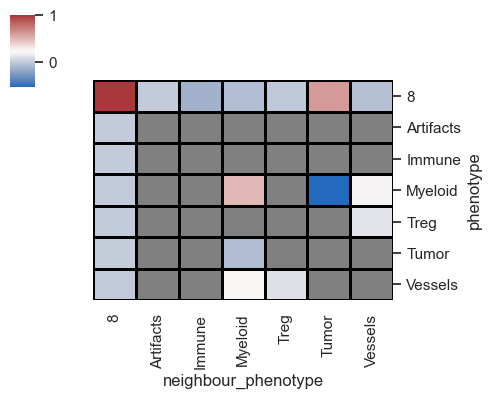

In [33]:
# view the results
sm.pl.spatial_interaction(
    adata, 
    # REMOVED: phenotype='leiden_phenotype',
    spatial_interaction='spatial_interaction_radius_roi',
    linewidths=0.75, 
    linecolor='black', 
    figsize=(5,4)
)


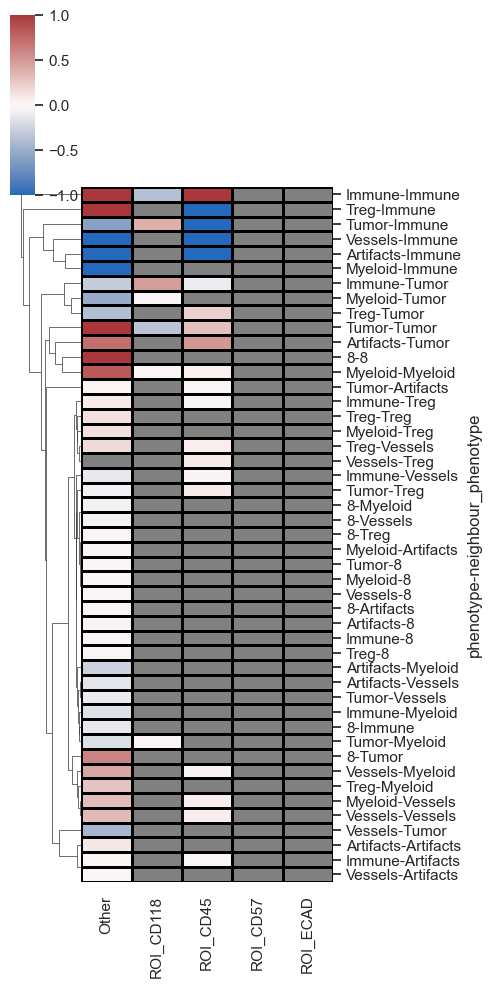

In [34]:
# visualize the data for each image individually by adding summarize_plot=False
sm.pl.spatial_interaction(adata, 
                          spatial_interaction='spatial_interaction_radius_roi',
                          yticklabels=True, figsize=(5,10), row_cluster=True,
                          summarize_plot=False,
                          linewidths=0.75, linecolor='black')

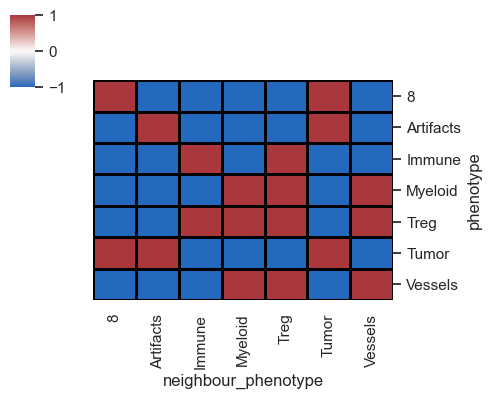

In [36]:
sm.pl.spatial_interaction(
    adata,
    # REMOVED: phenotype='leiden_phenotype',
    spatial_interaction='spatial_interaction_radius',  
    binary_view=True,
    linewidths=0.75, 
    linecolor='black', 
    figsize=(5,4)
)

c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\scipy\stats\_stats_py.py:9694: RuntimeWarning:

divide by zero encountered in log



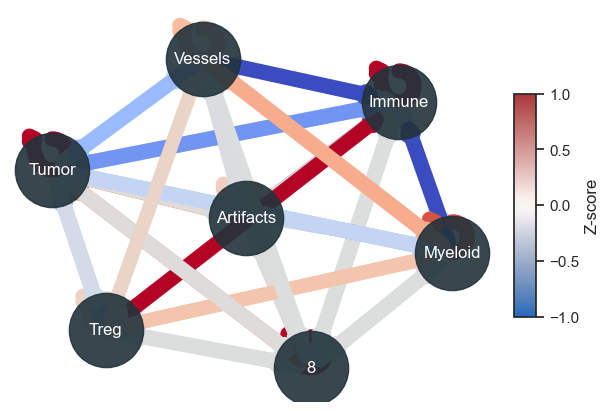

In [37]:
# Utilizing both distance and interaction plots together effectively highlights interacting cell partners in manuscripts.
# lastly we can also visualize the interactions as a network plot:
sm.pl.spatialInteractionNetwork(adata, spatial_interaction='spatial_interaction_radius', figsize=(6,4))

In [38]:
# Save the results
adata.write(r'C:\Users\chuab\Desktop\SciMap_project\scimapExampleData\scimapExampleData.h5ad')

⚖️ Tool for Computing Proximity Scores between Samples

In [39]:
# import packages
import scimap as sm
import anndata as ad
# Load the data that we saved in the last tutorial (with ROIs added)
adata = ad.read_h5ad(r'C:\Users\chuab\Desktop\SciMap_project\scimapExampleData\scimapExampleData.h5ad')

This analysis generates two key metrics: the Proximity Density and the Proximity Volume, both of which are saved in adata.uns.

1. Proximity Density reflects the ratio of identified interactions to the total number of cells of the interacting types, providing insight into how frequently these cell types interact relative to their population size.

2. Proximity Volume, on the other hand, compares the number of interactions to the total cell count in the dataset, offering a broader view of the interaction's significance across the entire sample.

Additionally, the locations of these interaction sites are recorded and saved in adata.obs, allowing for detailed spatial analysis. Running this analysis can elucidate the biological significance of the spatial arrangement of cell types, which is crucial for understanding tissue structure, function, and disease pathology in a more nuanced and quantitative manner.

In [43]:
adata = sm.tl.spatial_pscore(
    adata,
    proximity=['Tumor', 'Vessels'],  # Updated names
    score_by='ROI',
    phenotype='leiden_phenotype',
    method='radius',
    radius=50
)

Identifying neighbours within 50 pixels of every cell
Please check:
adata.obs['spatial_pscore'] &
adata.uns['spatial_pscore'] for results


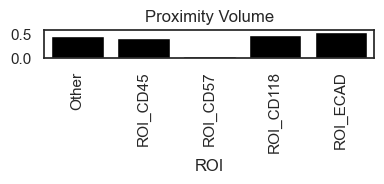

In [44]:
sm.pl.spatial_pscore (adata, color='black', plot_score='Proximity Volume', figsize=(4,2)) 

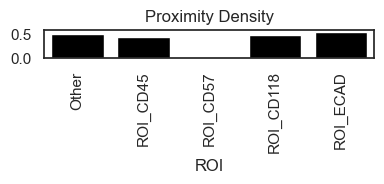

In [45]:
sm.pl.spatial_pscore (adata, color='Black', plot_score='Proximity Density', figsize=(4,2))

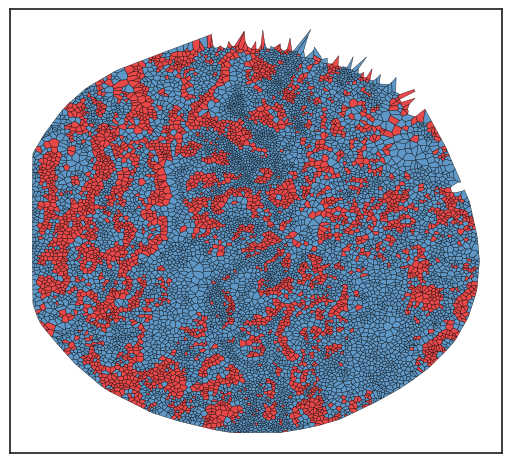

In [46]:
sm.pl.voronoi(adata, color_by='spatial_pscore', 
                 voronoi_edge_color = 'black',
                 size_max=3000,
                 voronoi_line_width = 0.3, 
                 voronoi_alpha = 0.8, 
                 overlay_points=None, 
                 plot_legend=True, 
                 legend_size=6)

In [47]:
# Save the results
adata.write(r'C:\Users\chuab\Desktop\SciMap_project\scimapExampleData\scimapExampleData.h5ad')

🔭 Tools to Search for Spatial Patterns

In [ ]:
# import packages
import scimap as sm
import anndata as ad
# Load the data that we saved in the last tutorial (with ROIs added)
adata = ad.read_h5ad(r'C:\Users\chuab\Desktop\SciMap_project\scimapExampleData\scimapExampleData.h5ad')


Ientify regions of Aggregation (single cell type)

The "sm.tl.spatial_aggregate" function identifies spatial clusters of cells that share similar phenotypes throughout the tissue. For instance, it can be utilized to locate a tumor mass by adjusting the 'purity' parameter. This adjustment grants the ability to define the minimum required similarity percentage among cells within a certain radius to classify them as part of an aggregation region. Such precision in identifying areas of cellular aggregation enhances the analysis's accuracy. For example, once the tumor domain is pinpointed, its prevalence can be compared between treatment and control groups or across designated histological sites, facilitating a deeper understanding of the tumor's spatial dynamics and potential treatment impacts.

In [49]:
adata = sm.tl.spatial_aggregate(adata, phenotype='leiden_phenotype', method='radius', radius=50, purity=80, label='spatial_aggregate_radius')

Identifying neighbours within 50 pixels of every cell


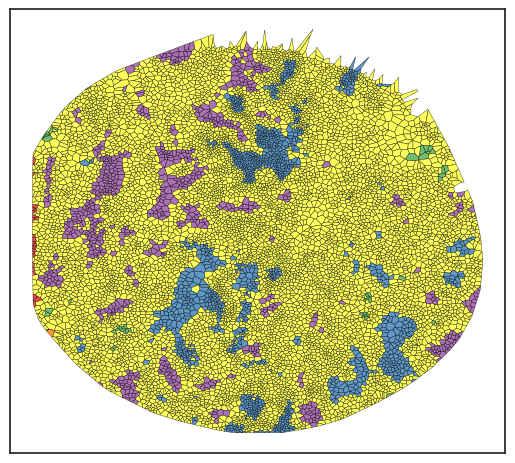

In [50]:
sm.pl.voronoi(adata, color_by='spatial_aggregate_radius', 
                 voronoi_edge_color = 'black',
                 voronoi_line_width = 0.3, 
                 voronoi_alpha = 0.8, 
                 size_max=3000,
                 overlay_points=None, 
                 plot_legend=True, 
                 legend_size=6)

Identify regions of Aggregation (multiple cell type)

What if your interest lies in pinpointing areas where two or more cell types are in close proximity, potentially indicating functional significance? In that case, we can utilize the spatial_pscore function. Although its primary aim is to provide a quantitative measure of proximity, it also highlights the specific tissue regions where these mixed cell types are located.

In [52]:
adata = sm.tl.spatial_pscore(
    adata,
    proximity=['Tumor', 'Vessels'],  # CHANGED: Use real names from your data
    phenotype='leiden_phenotype',
    method='radius',
    radius=50
)


Identifying neighbours within 50 pixels of every cell
Please check:
adata.obs['spatial_pscore'] &
adata.uns['spatial_pscore'] for results


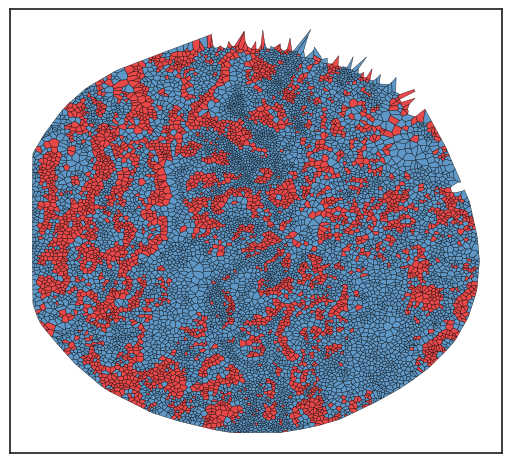

In [53]:
sm.pl.voronoi(adata, color_by='spatial_pscore', 
                 voronoi_edge_color = 'black',
                 voronoi_line_width = 0.3, 
                 voronoi_alpha = 0.8, 
                 size_max=3000,
                 overlay_points=None, 
                 plot_legend=True, 
                 legend_size=6)

Search for regions of Aggregation based on Similarity

What if you've spotted an area of interest in a raw image and wish to explore whether there are other regions within that image, or across the dataset, sharing the same molecular composition? For this task, the spatial_similarity_search function is your go-to tool. A preliminary step for using this function is identifying a Region of Interest (ROI), preferably a small one for better specificity, using the addROI_image function. This identified ROI then serves as the input for the spatial similarity search. It's important to note that if multiple ROIs are used, an average of these regions will be taken as the basis for the search. Therefore, it's generally recommended to be precise in defining your ROI to ensure the specificity of your search results.

In [55]:
print(adata.obs['ROI'].unique())


['Other', 'ROI_ECAD', 'ROI_CD45', 'ROI_CD118', 'ROI_CD57']
Categories (5, object): ['Other', 'ROI_CD45', 'ROI_CD57', 'ROI_CD118', 'ROI_ECAD']


In [56]:
adata = sm.tl.spatial_similarity_search(
    adata, 
    ROI_column='ROI', 
    similarity_threshold=0.4,
    ROI_subset=['ROI_ECAD'],  # Changed from 'ROI1' to match your data
    method='radius', 
    radius=40,
    label='tumor_similarity'
)


Identifying neighbours within 40 pixels of every cell


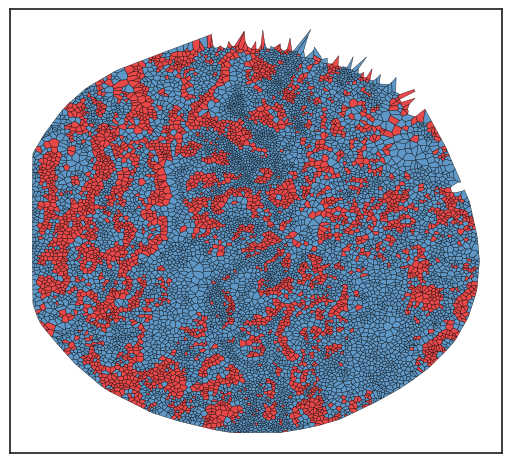

In [57]:
# Let's look at the regions identified by the method
sm.pl.voronoi(adata, color_by='spatial_pscore', 
                 voronoi_edge_color = 'black',
                 voronoi_line_width = 0.3, 
                 voronoi_alpha = 0.8, 
                 size_max=3000,
                 overlay_points=None, 
                 plot_legend=True, 
                 legend_size=6)

In [58]:
# Save the results
adata.write(r'C:\Users\chuab\Desktop\SciMap_project\scimapExampleData\scimapExampleData.h5ad')